# Group 22 — AI-Based Credit Card Fraud Detection
## Module 5: End-to-end implementation notebook

This notebook follows the Module 4 proposal and Module 5 implementation stages: define the problem, load and prepare data, perform EDA, build a baseline, compare/improve models, evaluate on an untouched test set, analyze errors, and test a simple prediction workflow.

**Dataset expected:** Kaggle ULB Credit Card Fraud Detection CSV, normally named `creditcard.csv`. It should contain `Time`, `Amount`, `V1`–`V28`, and `Class` (1 = fraud, 0 = legitimate).

**Important:** Run the notebook from top to bottom. Do not report any model score until you have run the cells and obtained your actual results. The notebook does not invent results.

## Step 0 — Install and import packages

Run the install cell once in Google Colab or your environment. Restart the runtime only if the environment asks you to.

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn joblib xgboost

In [2]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, confusion_matrix,
    classification_report, precision_recall_curve, RocCurveDisplay,
    PrecisionRecallDisplay
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## Step 1 — Define and refine the problem

- **Problem:** fraudulent credit-card transactions are rare and can be missed by simple rules.
- **Primary users:** fraud analysts and risk officers.
- **Input:** `Time`, `Amount`, and anonymized features `V1`–`V28`.
- **Target:** `Class`, where 1 means fraud and 0 means legitimate.
- **Output:** estimated fraud probability and a flag for review.
- **Main metrics:** recall, precision, F1-score, PR-AUC, ROC-AUC, and confusion matrix.
- **Decision support only:** a flagged transaction should be reviewed; this educational prototype is not a production banking system.

In [3]:
problem_definition = {
    "task": "Binary classification",
    "target": "Class (1 = fraud, 0 = legitimate)",
    "features": "Time, Amount, V1–V28",
    "primary_users": "Fraud analysts and risk officers",
    "output": "Fraud probability and review flag",
    "main_metrics": "Recall, Precision, F1, PR-AUC, ROC-AUC"
}
pd.Series(problem_definition, name="Project definition").to_frame()

,Project definition
task,Binary classification
target,"Class (1 = fraud, 0 = legitimate)"
features,"Time, Amount, V1–V28"
primary_users,Fraud analysts and risk officers
output,Fraud probability and review flag
main_metrics,"Recall, Precision, F1, PR-AUC, ROC-AUC"


## Step 2 — Load the dataset

Download `creditcard.csv` from the Kaggle ULB Credit Card Fraud Detection dataset and upload it to the notebook's working folder. In Google Colab, you can use the upload cell below instead of setting a path manually.

In [14]:

import os

for folder in ["/content", "/kaggle/input"]:
    if os.path.exists(folder):
        print(f"\nSearching in: {folder}")
        for root, dirs, files in os.walk(folder):
            for file in files:
                if file.lower() == "creditcard.csv":
                    print("FOUND:", os.path.join(root, file))



Searching in: /content

Searching in: /kaggle/input
FOUND: /kaggle/input/creditcardfraud/creditcard.csv


In [18]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

csv_files = [
    name for name in uploaded
    if name.lower().endswith(".csv")
]

if not csv_files:
    raise FileNotFoundError("Please upload the creditcard.csv file.")

DATA_PATH = csv_files[0]
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Saving creditcard.csv to creditcard.csv
Dataset loaded successfully!
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Step 3 — Inspect and check data quality

Check the dimensions, column names, data types, missing values, duplicates, descriptive statistics, target counts, and fraud percentage. Duplicate rows are reported first rather than automatically deleted: repeated-looking transactions may require domain review.

In [19]:
print("Rows and columns:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types and non-null counts:")
df_raw.info()

print("\nDescriptive statistics:")
display(df_raw.describe().T)

print("\nMissing values by column (top 15):")
display(df_raw.isna().sum().sort_values(ascending=False).head(15).to_frame("missing_count"))

print("\nExact duplicate rows:", int(df_raw.duplicated().sum()))

if "Class" not in df_raw.columns:
    raise ValueError("Target column 'Class' was not found. Check that the correct CSV is loaded.")

print("\nTarget counts:")
display(df_raw["Class"].value_counts(dropna=False).to_frame("count"))

print("\nTarget proportions:")
display((df_raw["Class"].value_counts(normalize=True, dropna=False) * 100).round(4).to_frame("percent"))

NameError: name 'df_raw' is not defined

In [21]:

# Check whether the dataset has already been loaded
if "df" in globals():
    df_raw = df.copy()
    print("Created df_raw from df.")
    print("Rows and columns:", df_raw.shape)

elif "DATA_PATH" in globals():
    import os
    import pandas as pd

    if os.path.exists(DATA_PATH):
        df_raw = pd.read_csv(DATA_PATH)
        print("Loaded dataset from:", DATA_PATH)
        print("Rows and columns:", df_raw.shape)
    else:
        raise FileNotFoundError(
            f"Dataset not found at {DATA_PATH}. Please check the file path."
        )

else:
    raise NameError(
        "Neither df nor DATA_PATH is available. Load the creditcard.csv dataset first."
    )

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types and non-null counts:")
df_raw.info()


Created df_raw from df.
Rows and columns: (284807, 31)

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 

## Step 4 — Prepare the data and document decisions

The expected file is numeric and normally has no missing values, but this code checks rather than assumes. We remove rows with a missing target because they cannot be used for supervised learning. Feature missing values, if any, will be imputed inside model pipelines to avoid preprocessing leakage. We do not automatically remove duplicate transactions; inspect them and document a justified decision if you choose to remove them.

In [22]:
df = df_raw.copy()

# Convert the target to numeric and remove rows whose target is missing/invalid.
df["Class"] = pd.to_numeric(df["Class"], errors="coerce")
before_target_clean = len(df)
df = df.dropna(subset=["Class"])
df = df[df["Class"].isin([0, 1])].copy()
df["Class"] = df["Class"].astype(int)

# Expected feature columns based on the proposal.
expected_features = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount"]
missing_expected = [c for c in expected_features if c not in df.columns]
if missing_expected:
    raise ValueError(f"Missing expected feature columns: {missing_expected}")

# Keep only the proposal's specified features and target.
df = df[expected_features + ["Class"]].copy()

# Convert feature columns to numeric. Unconvertible values become NaN and are imputed in pipelines.
for col in expected_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Rows before target cleaning:", before_target_clean)
print("Rows after target cleaning:", len(df))
print("Rows removed because target was missing/invalid:", before_target_clean - len(df))
print("Feature missing values (total):", int(df[expected_features].isna().sum().sum()))
print("Exact duplicate rows after target cleaning:", int(df.duplicated().sum()))

# Optional duplicate removal — leave False unless your group documents why duplicates should be removed.
REMOVE_EXACT_DUPLICATES = False
if REMOVE_EXACT_DUPLICATES:
    n_before = len(df)
    df = df.drop_duplicates().copy()
    print("Exact duplicates removed:", n_before - len(df))
else:
    print("Exact duplicates retained pending investigation.")

X = df[expected_features]
y = df["Class"]

print("Final modeling shape:", X.shape)
print("Fraud cases:", int(y.sum()))
print("Fraud prevalence (%):", round(y.mean() * 100, 4))

Rows before target cleaning: 284807
Rows after target cleaning: 284807
Rows removed because target was missing/invalid: 0
Feature missing values (total): 0
Exact duplicate rows after target cleaning: 1081
Exact duplicates retained pending investigation.
Final modeling shape: (284807, 30)
Fraud cases: 492
Fraud prevalence (%): 0.1727


## Step 5 — Exploratory Data Analysis (EDA)

Each plot should answer a question and be followed by an interpretation based on the actual output. Because the fraud class is very rare, use percentages and logarithmic scales where appropriate.

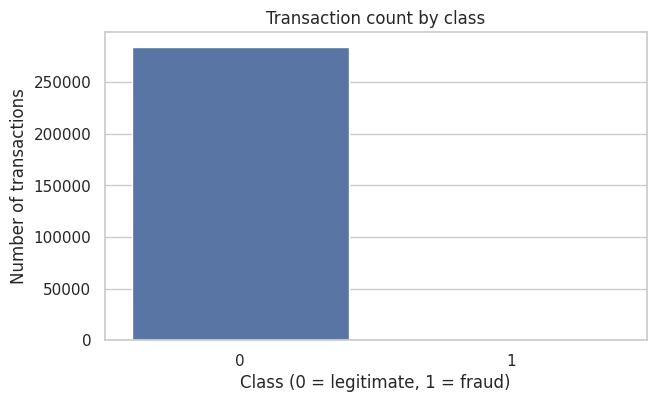

Fraud share: 0.1727%
Interpretation prompt: The chart should show how rare fraud is. This imbalance makes accuracy alone misleading.


In [23]:
# 5.1 Class distribution
class_counts = df["Class"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=class_counts.index.astype(str), y=class_counts.values, ax=ax)
ax.set_title("Transaction count by class")
ax.set_xlabel("Class (0 = legitimate, 1 = fraud)")
ax.set_ylabel("Number of transactions")
plt.show()

print("Fraud share:", f"{100 * y.mean():.4f}%")
print("Interpretation prompt: The chart should show how rare fraud is. This imbalance makes accuracy alone misleading.")

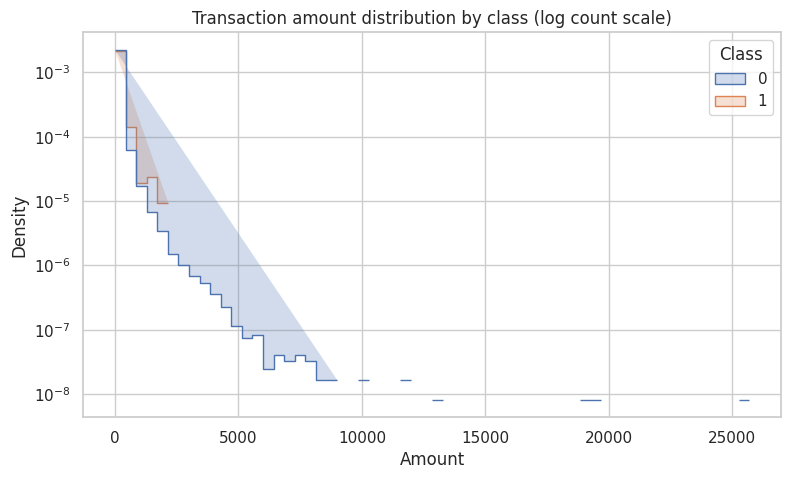

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291,250.105,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211,256.683,0.0,1.00,9.25,105.89,2125.87


Interpretation prompt: Compare the amount ranges, medians, and spread. Overlap means Amount alone is unlikely to be sufficient.


In [24]:
# 5.2 Amount distributions: compare legitimate and fraudulent transactions
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x="Amount", hue="Class", bins=60, stat="density",
             common_norm=False, element="step", log_scale=(False, True), ax=ax)
ax.set_title("Transaction amount distribution by class (log count scale)")
plt.show()

display(df.groupby("Class")["Amount"].describe().round(3))
print("Interpretation prompt: Compare the amount ranges, medians, and spread. Overlap means Amount alone is unlikely to be sufficient.")

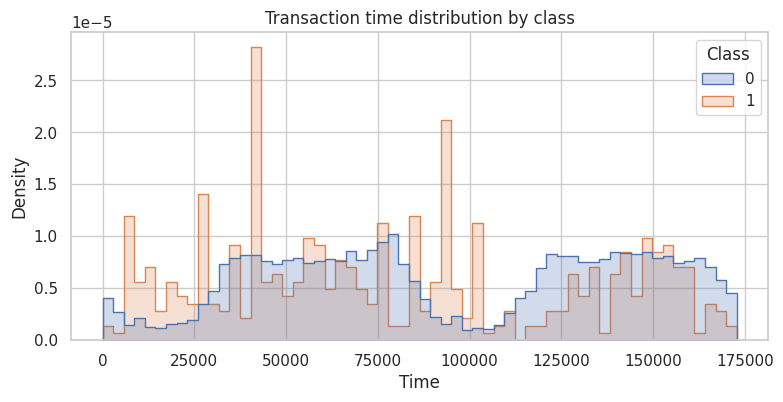

Interpretation prompt: Look for differences in the timing distribution. Time is seconds from the dataset's first transaction, not a calendar timestamp.


In [25]:
# 5.3 Time distribution
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x="Time", hue="Class", bins=60, element="step",
             stat="density", common_norm=False, ax=ax)
ax.set_title("Transaction time distribution by class")
plt.show()
print("Interpretation prompt: Look for differences in the timing distribution. Time is seconds from the dataset's first transaction, not a calendar timestamp.")

,lowest_corr,highest_corr
V17,-0.326481,NaN
V14,-0.302544,NaN
V12,-0.260593,NaN
V10,-0.216883,NaN
V16,-0.196539,NaN
V3,-0.192961,NaN
V7,-0.187257,NaN
V18,-0.111485,NaN
V1,-0.101347,NaN
V9,-0.097733,NaN


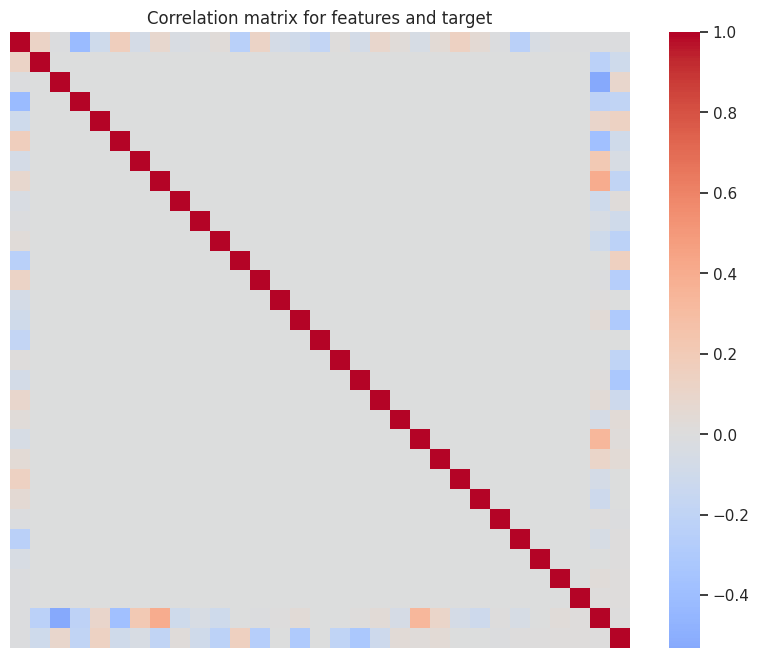

Interpretation prompt: Correlation can identify associations, but low linear correlation does not prove a feature is useless.


In [26]:
# 5.4 Correlation with target (descriptive, not proof of causality)
corr = df[expected_features + ["Class"]].corr(numeric_only=True)
target_corr = corr["Class"].drop("Class").sort_values()
display(pd.concat([target_corr.head(10).rename("lowest_corr"), target_corr.tail(10).rename("highest_corr")], axis=1))

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=False, yticklabels=False)
plt.title("Correlation matrix for features and target")
plt.show()
print("Interpretation prompt: Correlation can identify associations, but low linear correlation does not prove a feature is useless.")

In [27]:
# 5.5 Descriptive statistics for Amount and Time by class
display(df.groupby("Class")[["Time", "Amount"]].agg(["mean", "median", "std", "min", "max"]).round(3))

Time                                        Amount         \
            mean   median        std    min       max     mean median   
Class                                                                   
0      94838.202  84711.0  47484.016    0.0  172792.0   88.291  22.00   
1      80746.807  75568.5  47835.365  406.0  170348.0  122.211   9.25   

                               
           std  min       max  
Class                          
0      250.105  0.0  25691.16  
1      256.683  0.0   2125.87

### EDA summary — fill this in after viewing the outputs

Do not leave generic claims unsupported. Record your actual findings:
1. Fraud prevalence: copy the printed percentage.
2. Missing values and duplicates: report counts and your decision.
3. Amount/Time: describe visible differences and overlap.
4. Modeling implications: severe imbalance; use class weighting and/or training-only resampling, and report precision/recall/PR-AUC rather than accuracy alone.
5. Limitations: `V1`–`V28` are anonymized, and the dataset is historical European transaction data, so results may not transfer directly to Ethiopian banking.

## Step 6 — Split into training, validation, and test sets

The Module 4 proposal specifies a stratified 60% / 20% / 20% split. The validation set is used for model selection and threshold tuning. The test set is held untouched until the final evaluation. No resampling is applied to validation or test data.

In [28]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    "partition": ["train", "validation", "test"],
    "rows": [len(X_train), len(X_val), len(X_test)],
    "fraud_cases": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "fraud_percent": [100*y_train.mean(), 100*y_val.mean(), 100*y_test.mean()]
})
display(split_summary.round(4))

,partition,rows,fraud_cases,fraud_percent
0,train,170884,295,0.1726
1,validation,56961,98,0.1720
2,test,56962,99,0.1738


## Step 7 — Build the baseline models

We compare a trivial majority-class classifier and Logistic Regression. Logistic Regression uses median imputation and standardization inside a pipeline, so preprocessing is fitted on training data only. Class weighting is used to address imbalance without altering validation/test data.

In [29]:
def metric_row(name, y_true, y_pred, y_score=None):
    row = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }
    if y_score is not None:
        row["pr_auc"] = average_precision_score(y_true, y_score)
        row["roc_auc"] = roc_auc_score(y_true, y_score)
    else:
        row["pr_auc"] = np.nan
        row["roc_auc"] = np.nan
    return row

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_val)
baseline_rows = [metric_row("Majority-class baseline", y_val, dummy_pred)]

log_reg = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])
log_reg.fit(X_train, y_train)
log_val_prob = log_reg.predict_proba(X_val)[:, 1]
log_val_pred = (log_val_prob >= 0.5).astype(int)
baseline_rows.append(metric_row("Logistic Regression (threshold=0.50)", y_val, log_val_pred, log_val_prob))

baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results.round(4))

,model,accuracy,precision,recall,f1,pr_auc,roc_auc
0,Majority-class baseline,0.9983,0.000,0.0000,0.000,NaN,NaN
1,Logistic Regression (threshold=0.50),0.9781,0.065,0.8776,0.121,0.6857,0.9806


## Step 8 — Train and compare improved models

We compare Logistic Regression, Random Forest, and XGBoost when XGBoost is installed. Models use class weighting (or `scale_pos_weight` for XGBoost). The same train/validation partitions and metrics are used for a fair comparison. This cell may take some time.

In [30]:
models = {
    "Logistic Regression": log_reg,
    "Random Forest": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=250,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])
}

try:
    from xgboost import XGBClassifier
    neg, pos = np.bincount(y_train.astype(int), minlength=2)
    scale_pos_weight = neg / max(pos, 1)
    models["XGBoost"] = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="binary:logistic",
            eval_metric="aucpr",
            scale_pos_weight=scale_pos_weight,
            tree_method="hist",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])
except Exception as e:
    print("XGBoost is not available in this environment; comparing Logistic Regression and Random Forest only.")
    print("Reason:", repr(e))

fitted_models = {}
comparison_rows = []

for name, model in models.items():
    print("Training:", name)
    model.fit(X_train, y_train)
    fitted_models[name] = model
    val_prob = model.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= 0.5).astype(int)
    comparison_rows.append(metric_row(name + " (threshold=0.50)", y_val, val_pred, val_prob))

comparison = pd.DataFrame(comparison_rows).sort_values("pr_auc", ascending=False)
display(comparison.round(4))

Training: Logistic Regression
Training: Random Forest
Training: XGBoost


,model,accuracy,precision,recall,f1,pr_auc,roc_auc
2,XGBoost (threshold=0.50),0.9988,0.6090,0.8265,0.7013,0.8072,0.9831
1,Random Forest (threshold=0.50),0.9994,0.9211,0.7143,0.8046,0.7928,0.9503
0,Logistic Regression (threshold=0.50),0.9781,0.0650,0.8776,0.1210,0.6857,0.9806


## Step 9 — Select a model and tune the decision threshold using validation data

A probability threshold of 0.50 is not automatically appropriate for rare fraud. We select the candidate with the highest validation PR-AUC, then search thresholds on the validation set. The default selection rule prefers a threshold achieving recall ≥ 0.85 and precision ≥ 0.50 (the proposal's metrics table); if no threshold satisfies both, it selects the threshold with the highest F1-score. If your instructor expects the stricter business objective from the proposal (recall ≥ 0.90 and precision ≥ 0.60), change the two constants below and report whether the target is achievable.

Do not use the test set to choose the model or threshold.

In [31]:
best_name = comparison.iloc[0]["model"].replace(" (threshold=0.50)", "")
best_model = fitted_models[best_name]
print("Selected candidate by validation PR-AUC:", best_name)

val_prob = best_model.predict_proba(X_val)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_val, val_prob)

MIN_RECALL = 0.85
MIN_PRECISION = 0.50

# precision/recall arrays have one more element than thresholds; align to threshold candidates.
p = precisions[:-1]
r = recalls[:-1]
f1s = 2 * p * r / (p + r + 1e-12)

threshold_table = pd.DataFrame({
    "threshold": thresholds,
    "precision": p,
    "recall": r,
    "f1": f1s
})

eligible = threshold_table[
    (threshold_table["recall"] >= MIN_RECALL) &
    (threshold_table["precision"] >= MIN_PRECISION)
]

if not eligible.empty:
    chosen = eligible.sort_values(["f1", "precision"], ascending=False).iloc[0]
    threshold_reason = f"Highest F1 among thresholds meeting recall >= {MIN_RECALL:.2f} and precision >= {MIN_PRECISION:.2f}"
else:
    chosen = threshold_table.loc[threshold_table["f1"].idxmax()]
    threshold_reason = "No threshold met both targets; selected threshold with highest validation F1"

BEST_THRESHOLD = float(chosen["threshold"])
print("Chosen threshold:", BEST_THRESHOLD)
print("Selection reason:", threshold_reason)
display(chosen.to_frame("selected validation threshold"))

Selected candidate by validation PR-AUC: XGBoost
Chosen threshold: 0.9330846071243286
Selection reason: No threshold met both targets; selected threshold with highest validation F1


,selected validation threshold
threshold,0.933085
precision,0.873563
recall,0.775510
f1,0.821622


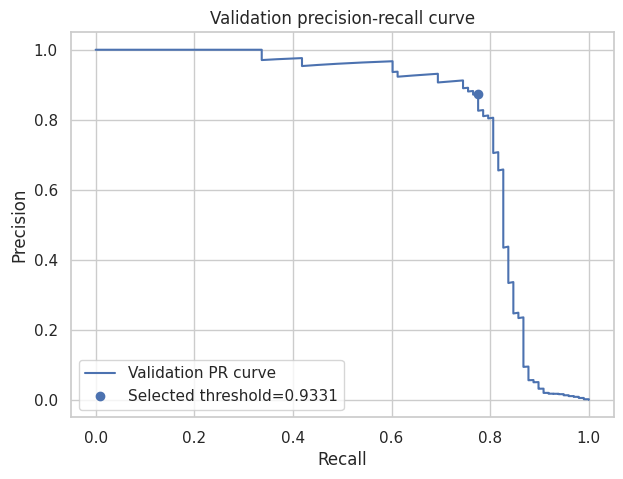

In [32]:
# Plot validation precision-recall curve and mark selected threshold
plt.figure(figsize=(7, 5))
plt.plot(recalls, precisions, label="Validation PR curve")
plt.scatter([chosen["recall"]], [chosen["precision"]], label=f"Selected threshold={BEST_THRESHOLD:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation precision-recall curve")
plt.legend()
plt.show()

## Step 10 — Final evaluation on the untouched test set

Only after model and threshold selection are complete do we evaluate the chosen model on the test set. These are the final independent test metrics for this run. Do not tune again based on test performance.

,model,accuracy,precision,recall,f1,pr_auc,roc_auc
0,XGBoost,0.9995,0.8977,0.798,0.8449,0.8557,0.9763


Classification report:
                precision    recall  f1-score   support

Legitimate (0)       1.00      1.00      1.00     56863
     Fraud (1)       0.90      0.80      0.84        99

      accuracy                           1.00     56962
     macro avg       0.95      0.90      0.92     56962
  weighted avg       1.00      1.00      1.00     56962



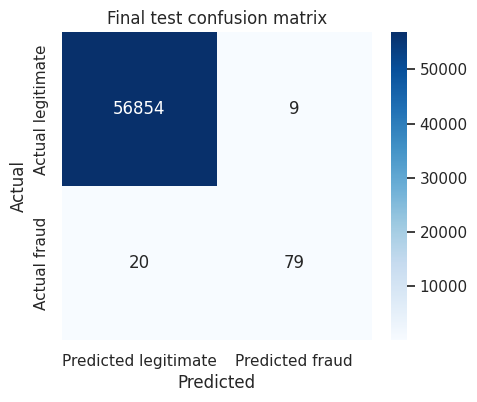

Confusion matrix order [[TN, FP], [FN, TP]]:
[[56854     9]
 [   20    79]]


In [33]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= BEST_THRESHOLD).astype(int)

final_metrics = pd.DataFrame([metric_row(best_name, y_test, test_pred, test_prob)])
display(final_metrics.round(4))

print("Classification report:")
print(classification_report(y_test, test_pred, target_names=["Legitimate (0)", "Fraud (1)"], zero_division=0))

cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted legitimate", "Predicted fraud"],
            yticklabels=["Actual legitimate", "Actual fraud"])
plt.title("Final test confusion matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

print("Confusion matrix order [[TN, FP], [FN, TP]]:")
print(cm)

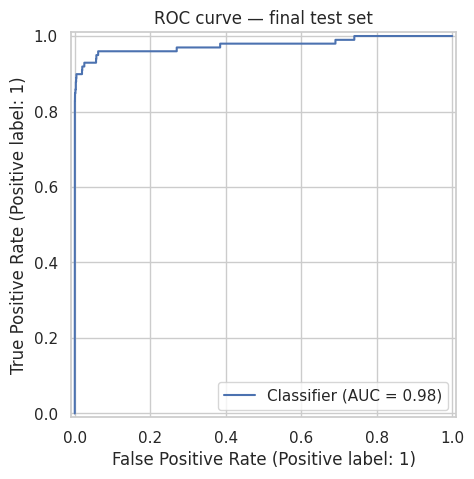

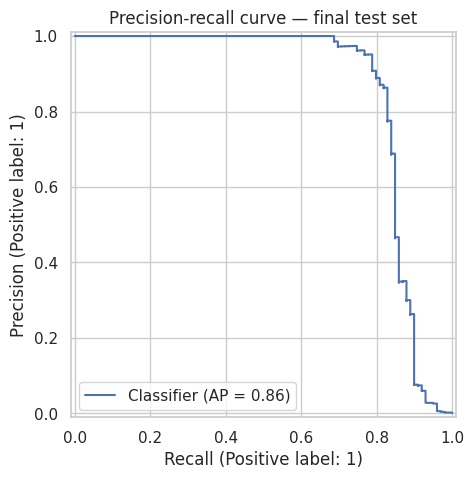

In [34]:
# ROC and precision-recall curves on the test set (for reporting only)
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, test_prob, ax=ax)
ax.set_title("ROC curve — final test set")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=ax)
ax.set_title("Precision-recall curve — final test set")
plt.show()

## Step 11 — Error analysis

Inspect false positives (legitimate transactions flagged for review) and false negatives (fraud missed by the model). Use this analysis to discuss practical trade-offs. Since `V1`–`V28` are anonymized, the records cannot be explained in normal business terms using this dataset alone.

In [35]:
error_analysis = X_test.copy()
error_analysis["actual_Class"] = y_test
error_analysis["fraud_probability"] = test_prob
error_analysis["predicted_Class"] = test_pred

false_positives = error_analysis[
    (error_analysis["actual_Class"] == 0) & (error_analysis["predicted_Class"] == 1)
].sort_values("fraud_probability", ascending=False)

false_negatives = error_analysis[
    (error_analysis["actual_Class"] == 1) & (error_analysis["predicted_Class"] == 0)
].sort_values("fraud_probability", ascending=True)

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))
print("\nHighest-scoring false positives:")
display(false_positives.head(10))
print("\nFalse negatives (missed fraud cases):")
display(false_negatives.head(10))

False positives: 9
False negatives: 20

Highest-scoring false positives:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,actual_Class,fraud_probability,predicted_Class
43432,41508.0,-32.273470,17.930550,-32.454198,6.555152,-23.236403,-4.487066,-22.030417,18.282168,-3.797563,-8.102120,3.492832,-4.748331,1.366199,-3.689181,-0.266118,-4.606720,-10.515507,-4.539148,0.332820,2.418001,0.581454,-1.931440,-0.895689,0.143893,2.343341,-0.211100,1.129057,0.377602,89.99,0,0.999052,1
10456,17044.0,-1.686955,4.081249,-7.770538,5.565240,-3.701602,-3.124916,-7.848606,1.748217,-3.270511,-11.208723,10.002190,-15.144988,-0.213782,-13.780377,-0.459420,-10.053112,-17.098444,-5.366660,1.661719,1.299638,1.393142,-0.543608,-0.317855,-0.015527,1.178955,-0.205649,1.911967,0.950716,1.00,0,0.998960,1
153398,98904.0,-2.690251,1.465266,-0.691844,4.322855,-1.086880,0.063585,-2.966872,-0.059646,-0.090827,-1.291980,2.969599,-6.835634,-0.226037,-2.484695,-2.207474,-1.883016,-6.675449,-1.273625,-1.161245,-0.632750,1.211390,0.259112,0.610188,-0.119366,0.028077,-0.044074,0.005614,0.557189,0.00,0,0.997862,1
153457,99129.0,-3.141115,2.014154,-0.610409,5.946659,-1.868534,0.756737,-3.313842,0.227978,-0.937894,-0.976492,3.050599,-6.930605,0.118405,-1.931536,-0.569347,-2.976084,-5.396702,-0.780563,1.906558,-0.563324,1.408511,0.800389,0.514926,-0.049373,-0.510364,0.442583,-0.165737,0.682784,45.51,0,0.994092,1
61140,49683.0,-6.325424,-3.216721,-3.701040,1.350842,-1.641233,-1.350805,-0.839809,0.419060,-0.974222,-3.139377,-0.019562,-3.650915,-0.710744,-2.063865,0.845533,-1.437617,-5.602616,-2.033763,0.618284,-1.318551,-0.005355,-0.711785,-2.691628,-0.268901,-0.617584,0.825943,0.823635,-0.788908,508.00,0,0.981822,1
19145,30047.0,-5.345558,5.116875,-9.270055,4.151766,-4.839258,-3.001705,-5.982505,3.892781,-2.587959,-6.624982,3.546377,-7.367772,-1.051471,-8.777934,0.998339,-4.906529,-8.125767,-2.644697,0.834801,0.812660,0.902817,-0.491616,0.217218,-0.065900,0.197834,-0.277323,1.242472,0.281893,89.99,0,0.974695,1
18649,29664.0,-4.815370,4.611247,-8.629997,4.185748,-3.852799,-3.339004,-6.241009,3.550544,-2.566085,-6.612556,3.653294,-7.478562,-1.130144,-8.990897,1.009183,-5.065037,-8.255208,-2.674511,0.862578,0.925830,0.949842,-0.510082,-0.072154,-0.059250,0.058823,-0.296556,1.180048,0.340171,1.00,0,0.969917,1
18150,29234.0,-4.171674,4.308450,-8.239315,4.168997,-3.855552,-3.023051,-5.521171,3.046835,-2.612760,-6.746047,3.789346,-7.683643,-1.189551,-9.257521,1.036380,-5.139197,-8.430967,-2.696048,0.901397,0.818596,0.902861,-0.448209,-0.061721,-0.052563,0.004487,-0.293409,1.281466,0.307834,89.99,0,0.945907,1
191296,129198.0,1.409526,0.804290,-1.132910,4.389033,-0.713480,0.381632,-1.949727,0.481483,-1.029737,-0.309069,-0.678748,-2.285944,0.603204,-2.538397,-0.619315,-0.733171,-4.691921,-1.231856,-1.143013,0.005499,0.472801,0.690423,0.057314,-0.669954,-0.012138,0.141410,0.355679,0.113299,0.00,0,0.938111,1



False negatives (missed fraud cases):


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,actual_Class,fraud_probability,predicted_Class
50537,44532.0,-0.234922,0.355413,1.972183,-1.255593,-0.681387,-0.665732,0.059110,-0.003153,1.122451,-1.481246,-0.473852,0.922184,0.913514,-0.499350,0.933898,-0.560472,-0.207707,0.380542,0.574336,-0.003469,0.220670,0.912107,-0.286338,0.451208,0.188315,-0.531846,0.123185,0.039581,1.00,1,0.000086,0
100623,67571.0,-0.758469,-0.045410,-0.168438,-1.313275,-1.901763,0.739433,3.071892,-0.483422,0.618203,-1.769060,-0.651414,-0.005423,-0.517194,0.217470,0.883559,-1.173978,0.243347,-0.342301,0.687056,-0.032500,0.042619,0.397224,0.072229,-0.242276,0.560916,-0.540955,0.150606,-0.117140,549.06,1,0.000107,0
72757,54846.0,-2.986466,-0.000891,0.605887,0.338338,0.685448,-1.581954,0.504206,-0.233403,0.636768,1.010291,0.004518,0.044397,0.420853,-0.931614,1.147974,0.483063,-0.152471,-0.285666,0.072550,-0.764274,-0.875146,-0.509849,1.313918,0.355065,0.448552,0.193490,1.214588,-0.013923,1.79,1,0.000409,0
219025,141565.0,0.114965,0.766762,-0.494132,0.116772,0.868169,-0.477982,0.438496,0.063073,-0.186207,-0.159325,1.200304,0.281744,-0.623844,-0.658246,-0.155888,0.056227,0.653662,0.334655,1.028927,0.062199,-0.284413,-0.706865,0.131405,0.600742,-0.604264,0.262938,0.099145,0.010810,4.49,1,0.000780,0
222419,142961.0,0.457845,1.373769,-0.488926,2.805351,1.777386,0.100492,1.295016,-0.135857,-1.695822,0.955004,-1.702228,-0.240056,0.456475,0.139567,-1.890974,0.372379,-0.798201,-0.697062,-1.497152,-0.264705,0.105593,0.371014,0.051105,0.401524,-0.724766,-0.202881,0.092124,0.094956,0.00,1,0.005510,0
191074,129095.0,-1.836940,-1.646764,-3.381168,0.473354,0.074243,-0.446751,3.791907,-1.351045,0.095186,-0.084500,-1.542305,-0.540535,-0.272079,0.712541,0.234980,-0.907666,-0.391051,-0.034719,1.084286,-1.586144,0.010663,1.786681,-0.151178,-0.582098,-0.956062,-0.334369,0.715600,0.370450,720.80,1,0.006053,0
275992,166831.0,-2.027135,-1.131890,-1.135194,1.086963,-0.010547,0.423797,3.790880,-1.155595,-0.063434,1.334414,1.032016,-0.722023,-1.533240,0.334119,0.297479,-0.429392,-0.824644,0.489668,0.873344,0.033804,-0.315105,0.575520,0.490842,0.756502,-0.142685,-0.602777,0.508712,-0.091646,634.30,1,0.006154,0
213092,139107.0,-4.666500,-3.952320,0.206094,5.153525,5.229469,0.939040,-0.635033,-0.704506,-0.234786,4.031435,0.983647,-0.578914,-0.199814,-0.729707,1.266713,-0.842769,-0.102946,-0.597597,1.060154,-2.286137,-0.664263,1.821422,0.113563,-0.759673,-0.502304,0.630639,-0.513880,0.729526,22.47,1,0.015071,0
281674,170348.0,1.991976,0.158476,-2.583441,0.408670,1.151147,-0.096695,0.223050,-0.068384,0.577829,-0.888722,0.491140,0.728903,0.380428,-1.948883,-0.832498,0.519436,0.903562,1.197315,0.593509,-0.017652,-0.164350,-0.295135,-0.072173,-0.450261,0.313267,-0.289617,0.002988,-0.015309,42.53,1,0.020084,0
58422,48380.0,-2.790771,-1.464269,1.031165,1.921356,-0.090014,-0.483871,0.780731,-0.348776,0.609133,0.225934,-1.064534,-0.787373,-1.576470,-0.126756,0.367012,-0.635322,0.327006,0.043816,1.403574,-1.376721,-0.392667,0.440020,0.777659,0.418552,0.244563,-0.159361,0.060540,0.356958,208.58,1,0.021141,0


In [36]:
# Compare Amount summaries for TP, FP, FN, TN
error_analysis["outcome"] = np.select(
    [
        (error_analysis.actual_Class == 1) & (error_analysis.predicted_Class == 1),
        (error_analysis.actual_Class == 0) & (error_analysis.predicted_Class == 1),
        (error_analysis.actual_Class == 1) & (error_analysis.predicted_Class == 0),
        (error_analysis.actual_Class == 0) & (error_analysis.predicted_Class == 0),
    ],
    ["TP", "FP", "FN", "TN"],
    default="Unknown"
)
display(error_analysis.groupby("outcome").agg(
    transactions=("Amount", "size"),
    mean_amount=("Amount", "mean"),
    median_amount=("Amount", "median"),
    mean_probability=("fraud_probability", "mean")
).round(3))

,transactions,mean_amount,median_amount,mean_probability
outcome,,,,
FN,20,137.198,15.215,0.232
FP,9,91.720,45.510,0.978
TN,56854,88.066,21.810,0.003
TP,79,90.258,23.360,0.999


## Step 12 — Basic model improvement / tuning log

The model comparison and threshold search above are the first improvement experiments. The following optional small grid searches a few Random Forest settings using training data and cross-validation with average precision (PR-AUC-style scoring). It may take time. Do not run it unless needed, and do not use test scores to select parameters.

In [38]:
# OPTIONAL: modest Random Forest tuning. Run if time/resources allow.
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer

rf_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

param_distributions = {
    "model__n_estimators": [150, 250],
    "model__max_depth": [None, 8, 14],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", 0.7]
}

search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=6,
    scoring="average_precision",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

# Uncomment the next two lines to run the optional search:
# search.fit(X_train, y_train)
# print("Best CV average precision:", search.best_score_, "\nBest parameters:", search.best_params_)

## Step 13 — Test the complete prediction workflow

This stage checks input validation, preprocessing, prediction, and output. It tests a valid row, a missing value, an invalid string, and an extreme numeric value. The model itself is not a substitute for production validation or monitoring.

In [39]:
# A valid example based on an existing test row
sample_input = X_test.iloc[[0]].copy()

def predict_transaction(input_df, model=best_model, threshold=BEST_THRESHOLD):
    required = list(expected_features)

    if not isinstance(input_df, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame.")
    missing_cols = [c for c in required if c not in input_df.columns]
    extra_cols = [c for c in input_df.columns if c not in required]
    if missing_cols:
        raise ValueError(f"Missing required feature columns: {missing_cols}")
    if extra_cols:
        raise ValueError(f"Unexpected columns supplied: {extra_cols}")

    clean = input_df[required].copy()
    for col in required:
        clean[col] = pd.to_numeric(clean[col], errors="coerce")

    # Allow missing values because the trained pipeline imputes them,
    # but reject rows where every feature is missing.
    if clean.isna().all(axis=1).any():
        raise ValueError("At least one input row has no usable numeric features.")

    probabilities = model.predict_proba(clean)[:, 1]
    flags = (probabilities >= threshold).astype(int)

    return pd.DataFrame({
        "fraud_probability": probabilities,
        "predicted_Class": flags,
        "decision": np.where(flags == 1, "FLAG FOR ANALYST REVIEW", "NOT FLAGGED")
    })

display(predict_transaction(sample_input))

,fraud_probability,predicted_Class,decision
0,0.001084,0,NOT FLAGGED


In [40]:
# Test A: missing value — should be handled by the pipeline imputer
test_missing = sample_input.copy()
test_missing.loc[test_missing.index[0], "Amount"] = np.nan
try:
    display(predict_transaction(test_missing))
    print("Missing-value test: handled by the pipeline.")
except Exception as e:
    print("Missing-value test: failed:", e)

# Test B: invalid string — converted to NaN and imputed; record this behavior.
test_invalid_numeric = sample_input.copy()
test_invalid_numeric.loc[test_invalid_numeric.index[0], "Amount"] = "not-a-number"
try:
    display(predict_transaction(test_invalid_numeric))
    print("Invalid-number test: converted to missing and imputed. In production, you may prefer to reject it.")
except Exception as e:
    print("Invalid-number test: safely rejected:", e)

# Test C: missing required column — should be rejected.
test_missing_column = sample_input.drop(columns=["Amount"])
try:
    predict_transaction(test_missing_column)
    print("Missing-column test: UNEXPECTEDLY passed.")
except Exception as e:
    print("Missing-column test: correctly rejected:", e)

# Test D: extreme numeric value — prediction is produced, but flag it for review.
test_extreme = sample_input.copy()
test_extreme.loc[test_extreme.index[0], "Amount"] = 1_000_000_000
try:
    display(predict_transaction(test_extreme))
    print("Extreme-value test: prediction produced; a production system should also apply business-specific range checks.")
except Exception as e:
    print("Extreme-value test: rejected:", e)

,fraud_probability,predicted_Class,decision
0,0.000784,0,NOT FLAGGED


Missing-value test: handled by the pipeline.


,fraud_probability,predicted_Class,decision
0,0.000784,0,NOT FLAGGED


Invalid-number test: converted to missing and imputed. In production, you may prefer to reject it.
Missing-column test: correctly rejected: Missing required feature columns: ['Amount']


,fraud_probability,predicted_Class,decision
0,0.000976,0,NOT FLAGGED


Extreme-value test: prediction produced; a production system should also apply business-specific range checks.


## Step 14 — Save the selected model and project artifacts

Save the fitted pipeline, threshold, and feature list. Keep the same feature order and preprocessing when making future predictions.

In [41]:
os.makedirs("artifacts", exist_ok=True)

artifact = {
    "model": best_model,
    "threshold": BEST_THRESHOLD,
    "feature_names": expected_features,
    "target_name": "Class",
    "selected_model_name": best_name,
    "random_state": RANDOM_STATE
}
joblib.dump(artifact, "artifacts/fraud_detection_model.joblib")

final_metrics.to_csv("artifacts/final_test_metrics.csv", index=False)
comparison.to_csv("artifacts/validation_model_comparison.csv", index=False)
split_summary.to_csv("artifacts/data_split_summary.csv", index=False)

print("Saved:")
print("- artifacts/fraud_detection_model.joblib")
print("- artifacts/final_test_metrics.csv")
print("- artifacts/validation_model_comparison.csv")
print("- artifacts/data_split_summary.csv")

Saved:
- artifacts/fraud_detection_model.joblib
- artifacts/final_test_metrics.csv
- artifacts/validation_model_comparison.csv
- artifacts/data_split_summary.csv


## Step 15 — Optional minimal REST API prototype (Flask)

This is a small local demonstration only. Run the cell below to write `app.py`. Then run the command in a separate terminal. The endpoint expects JSON containing every feature from the model. Do not expose this demo to the internet or use it for real banking decisions without security, monitoring, privacy, and governance controls.

In [42]:
api_source = r'''
from flask import Flask, request, jsonify
import joblib
import pandas as pd
import numpy as np

app = Flask(__name__)
artifact = joblib.load("artifacts/fraud_detection_model.joblib")
model = artifact["model"]
threshold = float(artifact["threshold"])
features = artifact["feature_names"]

@app.get("/health")
def health():
    return jsonify({"status": "ok"})

@app.post("/predict")
def predict():
    payload = request.get_json(silent=True)
    if not isinstance(payload, dict):
        return jsonify({"error": "Send a JSON object with transaction features."}), 400

    missing = [c for c in features if c not in payload]
    extra = [c for c in payload if c not in features]
    if missing:
        return jsonify({"error": "Missing required features", "missing": missing}), 400
    if extra:
        return jsonify({"error": "Unexpected features", "extra": extra}), 400

    row = pd.DataFrame([{c: payload[c] for c in features}])
    for c in features:
        row[c] = pd.to_numeric(row[c], errors="coerce")
    if row.isna().all(axis=1).any():
        return jsonify({"error": "No usable numeric feature values."}), 400

    probability = float(model.predict_proba(row)[0, 1])
    flag = int(probability >= threshold)
    return jsonify({
        "fraud_probability": probability,
        "predicted_Class": flag,
        "decision": "FLAG FOR ANALYST REVIEW" if flag else "NOT FLAGGED",
        "threshold": threshold
    })

if __name__ == "__main__":
    app.run(host="127.0.0.1", port=5000, debug=False)
'''

with open("app.py", "w", encoding="utf-8") as f:
    f.write(api_source)

print("Created app.py")
print("To run in a terminal: python app.py")
print("Test health: GET http://127.0.0.1:5000/health")
print("POST JSON to http://127.0.0.1:5000/predict with all 30 feature fields.")

Created app.py
To run in a terminal: python app.py
Test health: GET http://127.0.0.1:5000/health
POST JSON to http://127.0.0.1:5000/predict with all 30 feature fields.


## Step 16 — Reporting checklist and team reflection

Use the real outputs generated by the notebook to complete the Module 5 report.

- [ ] Problem, users, inputs, target, outputs, and success criteria
- [ ] Dataset source, number of rows/features, target prevalence
- [ ] Missing-value and duplicate checks and documented decisions
- [ ] EDA charts with written interpretations
- [ ] Majority-class and Logistic Regression baselines
- [ ] Model comparison using the same validation set
- [ ] Threshold selection rationale based on validation data
- [ ] Final test metrics and confusion matrix, evaluated once
- [ ] False-positive / false-negative analysis
- [ ] Complete workflow tests and prototype demonstration
- [ ] Limitations: anonymized PCA features, historical European data, imbalance, potential domain shift
- [ ] Team contributions and what each member actually completed

**Do not claim the model meets a target unless the actual metrics show it.** If a target is missed, report it honestly and explain the trade-off.